# Module 2 · Partie 2 : ACP et détection des outliers spectraux

> Cours d'**Analyse multivariée 2 : Data Mining & Machine Learning** (Prof. H. Soyeurt, Gembloux Agro-Bio Tech, 2026-2027).
> Sources : syllabus *Validation, PCR and PLS* (`module2.pdf`, §2.2 et §3.5), exercice dirigé officiel *PLS_PCR_fatty_acids_20201007.Rmd* (§2), script `pca_fatty_acids.R`.

### Objectifs d'apprentissage
À la fin de ce notebook, tu sauras :
1. rappeler les **contraintes** qui définissent les composantes principales (combinaison linéaire, norme 1, variance maximale, orthogonalité) et le rôle des **vecteurs propres** et **valeurs propres** ;
2. réaliser une ACP de trois façons en R (`eigen()`, `prcomp()`, `FactoMineR::PCA()`) et comprendre pourquoi leurs sorties diffèrent légèrement ;
3. choisir un **nombre de composantes** à partir du pourcentage cumulé de variance ;
4. calculer la **distance de Mahalanobis** sur les composantes principales et la **distance GH** (*Global H*) ;
5. détecter les **outliers spectraux** (GH > 3 ou GH > 5) et nettoyer un jeu de calibration ;
6. évaluer le **potentiel de prédiction** d'un nouvel échantillon (est-il dans la variabilité de la calibration ?).

### Prérequis
Partie 0 du module 2 (jeux de données), module 1 (corrélation, colinéarité, CV par point spectral). L'ACP a été vue en détail dans le cours *Analyse multivariée 1* (STAT1213) : on n'en rappelle ici que ce qui sert pour la suite (PCR, distance GH).

### Sommaire
- 2.1 Pourquoi une ACP avant de modéliser ?
- 2.2 Rappels théoriques : les composantes principales
- 2.3 Trois façons de faire une ACP en R
- 2.4 ACP des spectres MIR du lait (acides gras)
- 2.5 La distance de Mahalanobis
- 2.6 La distance GH et le nettoyage du jeu de calibration
- 2.7 Potentiel de prédiction d'un nouvel échantillon
- Questions de compréhension
- Récapitulatif

In [1]:
# Packages utilisés dans ce notebook
suppressPackageStartupMessages({
  library(FactoMineR)  # PCA()
  library(ggplot2)     # heatmap de la matrice de covariance (comme le Rmd officiel)
  library(reshape2)    # melt() : matrice -> tableau long pour ggplot
  library(knitr)       # kable()
})
options(repr.plot.width = 10, repr.plot.height = 6)  # taille des figures dans Jupyter

---
## 2.1 Pourquoi une ACP avant de modéliser ?

Au homework 1, on a contrôlé la qualité des spectres **variable par variable** : coefficient de variation de chaque point spectral, recherche de régions bruitées. Cette approche est utile pour repérer des **régions** bruitées, mais elle ne permet pas de repérer un **échantillon** dont le spectre, pris dans son ensemble, est atypique : un spectre est composé de trop de variables (1 060) pour qu'on les inspecte une à une.

L'exercice dirigé officiel le résume ainsi :

> *When you have a large subset containing many features which can be highly correlated, the principal component analysis (PCA) is a relevant method to decrease the dimensionality of the X matrix in order to estimate the distance between samples. This distance calculation allows highlighting easily samples having a different behavior in a dataset.*

La démarche suivie dans ce notebook :

1. **ACP** sur les spectres standardisés → quelques dizaines de composantes résument presque toute l'information des 1 060 variables ;
2. **distance de Mahalanobis** de chaque échantillon au centre (barycentre) du nuage, calculée sur ces composantes ;
3. **distance GH** = Mahalanobis standardisée par le nombre de composantes → seuils 3 et 5 ;
4. retrait des **outliers spectraux** avant de construire les modèles (PCR en partie 3, PLS en partie 4).

> **Complément** : l'ACP sert aussi directement à la **régression** : c'est la première étape de la PCR (partie 3). Ce notebook pose donc les bases des deux usages.

---
## 2.2 Rappels théoriques : les composantes principales

L'ACP est une méthode **descriptive** et **non supervisée** (pas de variable *y*) qui étudie les relations entre variables quantitatives. Elle définit des **composantes principales**, indices synthétiques qui résument au mieux l'information contenue dans les données.

Si $p$ est le nombre de variables, les composantes doivent satisfaire **quatre contraintes** (syllabus §2.2) :

1. **Combinaison linéaire** des variables **centrées réduites**. Pour la première composante et l'individu $i$ :
$$z_{i1} = u_{11}\,x_{i1} + u_{21}\,x_{i2} + \dots + u_{p1}\,x_{ip}$$
2. **Norme unitaire** des coefficients :
$$u_{11}^2 + u_{21}^2 + \dots + u_{p1}^2 = 1$$
3. **Variance maximale** : les coefficients sont choisis pour que la variance de $z_{i1}$ soit maximale ; les composantes suivantes ont des variances décroissantes.
4. **Orthogonalité** (pour les composantes au-delà de la première) : la somme des produits des coefficients de deux combinaisons est nulle, par exemple
$$u_{11}u_{12} + u_{21}u_{22} + \dots + u_{p1}u_{p2} = 0$$

La contrainte 2 est une forme de standardisation **sans laquelle la contrainte 3 n'aurait pas de sens** : on pourrait toujours augmenter la variance d'une composante en multipliant tous ses coefficients par une constante arbitrairement grande.

> **Définition**
> - Le vecteur des coefficients $u_{\cdot k} = (u_{1k}, \dots, u_{pk})$ est le **vecteur propre** (*eigenvector*) de la composante $k$ (de la matrice de corrélation des variables).
> - La **valeur propre** (*eigenvalue*) $\lambda_k$ est la **variance** de la composante $k$.
> - Comme les variables sont réduites, la variance totale vaut $p$ : la composante $k$ explique $100\,\lambda_k / p$ % de la variabilité de X.

Conséquence clé pour la suite : grâce à la contrainte 4, les composantes sont **orthogonales**, donc **non corrélées** entre elles. C'est cette propriété qui, combinée à la régression linéaire classique, **résout le problème de colinéarité** (PCR, partie 3).

### 2.2.1 Vérification à la main sur l'exemple « octane » du syllabus

On reprend la Table 1 du syllabus : l'indice d'octane de 12 mélanges, en fonction des proportions de 7 composants (voir partie 0). On calcule les vecteurs et valeurs propres de la matrice de corrélation avec `eigen()`.

In [2]:
# Table 1 du syllabus (module2.pdf, §2.1) : 12 mélanges, 7 composants, indice d'octane
octane <- data.frame(
  X1 = c(0, 0, 0, 0, 0, 0, 0.17, 0.17, 0.17, 0.17, 0.21, 0),
  X2 = c(0.23, 0.1, 0, 0.49, 0, 0.62, 0.27, 0.19, 0.21, 0.15, 0.36, 0),
  X3 = c(0, 0, 0, 0, 0, 0, 0.1, 0.1, 0.1, 0.1, 0.12, 0),
  X4 = c(0, 0, 0.1, 0, 0.62, 0, 0.38, 0.38, 0.38, 0.38, 0.25, 0.55),
  X5 = c(0, 0.12, 0.12, 0.12, 0.12, 0, 0, 0.02, 0, 0.02, 0, 0),
  X6 = c(0.74, 0.74, 0.74, 0.37, 0.18, 0.37, 0, 0.06, 0.06, 0.1, 0, 0.37),
  X7 = c(0.03, 0.04, 0.04, 0.02, 0.08, 0.01, 0.08, 0.08, 0.08, 0.08, 0.06, 0.08),
  octane = c(98.7, 97.8, 96.6, 92, 86.6, 91.2, 81.9, 83.1, 82.4, 83.2, 81.4, 88.1))
X_oct <- as.matrix(octane[, 1:7])

e <- eigen(cor(X_oct))            # décomposition de la matrice de corrélation
round(e$values, 4)                # valeurs propres = variances des composantes
round(100 * e$values / 7, 2)      # % de variance expliquée (variance totale = p = 7)
round(100 * cumsum(e$values) / 7, 2)

[1] 4.0255 1.9104 0.5726 0.4782 0.0132 0.0001 0.0000

[1] 57.51 27.29  8.18  6.83  0.19  0.00  0.00

[1]  57.51  84.80  92.98  99.81 100.00 100.00 100.00

Les 4 premières composantes expliquent déjà 99.81 % de la variabilité des 7 composants, et 5 composantes en expliquent 100 % : on retrouve la ligne *X* de la Table 2 du syllabus (57.51, 84.80, 92.98, 99.81, 100…). La 7e valeur propre est **nulle** : les 7 proportions d'un mélange somment à 1, une des variables est donc une combinaison exacte des autres (colinéarité parfaite).

On vérifie maintenant les contraintes 2 et 4 et le lien « valeur propre = variance de la composante ».

In [3]:
U <- e$vectors                       # une colonne = un vecteur propre
colSums(U^2)                         # contrainte 2 : chaque vecteur est de norme 1
round(sum(U[, 1] * U[, 2]), 12)      # contrainte 4 : produit scalaire nul entre u1 et u2

Xs <- scale(X_oct)                   # variables centrées réduites
Z  <- Xs %*% U                       # scores (coordonnées) des 12 mélanges sur les 7 composantes
round(apply(Z, 2, var), 4)           # = valeurs propres
round(cor(Z[, 1:4]), 10)             # composantes non corrélées (matrice identité)

[1] 1 1 1 1 1 1 1

[1] 0

[1] 4.0255 1.9104 0.5726 0.4782 0.0132 0.0001 0.0000

1,0,0,0
0,1,0,0
0,0,1,0
0,0,0,1


### Exercice 2.1 : la première composante, coefficient par coefficient
1. Affiche les coefficients $u_{j1}$ de la première composante avec le nom de la variable correspondante.
2. Quelles variables contribuent le plus (en valeur absolue) à la première composante ? Compare avec la matrice de corrélation de la partie 0 : que remarques-tu pour X1 et X3 ?
3. Recalcule le score $z_{11}$ du premier mélange « à la main » (somme des produits) et vérifie qu'il est égal à `Z[1, 1]`.

In [4]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
u1 <- setNames(U[, 1], colnames(X_oct))
round(u1, 3)
round(sort(abs(u1), decreasing = TRUE), 3)
sum(u1 * Xs[1, ])      # z_11 à la main
Z[1, 1]
```

X1, X3 et X6 ont les plus gros coefficients en valeur absolue, suivis de X7 et X4. X1 et X3 ont des coefficients presque identiques : leur corrélation vaut 1.00 dans la matrice de corrélation, elles portent la même information et « pèsent » donc de la même façon dans la composante. Le signe global d'un vecteur propre est arbitraire (voir 2.3) : seules les positions relatives des coefficients comptent.

</details>

---
## 2.3 Trois façons de faire une ACP en R

| Fonction | Package | Ce qu'elle renvoie | Remarque |
|---|---|---|---|
| `eigen(cor(X))` | base | `$values`, `$vectors` | la définition « mathématique » |
| `prcomp(X, scale. = TRUE)` | stats (base) | `$sdev` (racine des valeurs propres), `$rotation` (vecteurs propres), `$x` (scores) | standardise avec l'écart-type en $n-1$ |
| `PCA(X, scale.unit = TRUE)` | FactoMineR | `$eig`, `$ind$coord`, `$var$coord`, `$var$cor`, `$svd$V` | utilisée dans le cours ; standardise avec l'écart-type en $n$ |

> **Fonction R** : `PCA(X, scale.unit = TRUE, ncp = 5, ind.sup = NULL, quanti.sup = NULL, graph = TRUE)` (FactoMineR)
>
> | Argument | Rôle |
> |---|---|
> | `X` | data.frame ou matrice des variables (lignes = individus) |
> | `scale.unit` | `TRUE` : variables centrées **réduites** (même poids pour toutes) ; `FALSE` : seulement centrées |
> | `ncp` | nombre de composantes **conservées** dans les résultats (5 par défaut) |
> | `ind.sup`, `quanti.sup` | individus ou variables supplémentaires (projetés, sans participer au calcul) |
> | `graph` | `TRUE` : trace automatiquement les graphes des individus et des variables |
>
> **Renvoie** une liste de classe `"PCA"` : `$eig` (valeurs propres, % de variance, % cumulé), `$ind$coord` (coordonnées des individus = scores), `$ind$cos2`, `$ind$contrib`, `$var$coord` (coordonnées des variables), `$var$cor` (corrélations variables–composantes), `$svd$V` (vecteurs propres), `$call` (moyennes et écarts-types utilisés). On projette de nouveaux individus avec `predict(res, newdata)`.

> **Attention** : dans le Rmd officiel, l'appel est `PCA(x, scale = TRUE)`. Il fonctionne parce que R complète les noms d'arguments partiels (`scale` → `scale.unit`), mais il vaut mieux écrire le nom complet.

In [5]:
res_oct <- PCA(X_oct, scale.unit = TRUE, ncp = 7, graph = FALSE)
round(res_oct$eig, 4)                       # mêmes valeurs propres qu'avec eigen()

round(cbind(eigen = U[, 1], FactoMineR = res_oct$svd$V[, 1]), 3)   # même vecteur, au signe près

,eigenvalue,percentage of variance,cumulative percentage of variance
comp 1,4.0255,57.5075,57.5075
comp 2,1.9104,27.2908,84.7983
comp 3,0.5726,8.1804,92.9787
comp 4,0.4782,6.8311,99.8097
comp 5,0.0132,0.1891,99.9988
comp 6,0.0001,0.0012,100.0000
comp 7,0.0000,0.0000,100.0000


eigen,FactoMineR
-0.446,0.446
0.061,-0.061
-0.447,0.447
-0.365,0.365
0.288,-0.288
0.448,-0.448
-0.424,0.424


Deux différences, sans conséquence sur l'interprétation :

- **Le signe** d'un vecteur propre est arbitraire : $u$ et $-u$ définissent le même axe. Selon l'algorithme, une composante peut être « retournée ».
- **L'échelle des scores** : `FactoMineR` réduit les variables avec l'écart-type **en $n$** (population), alors que `scale()` et `prcomp()` utilisent l'écart-type **en $n-1$**. Les coordonnées de `FactoMineR` sont donc multipliées par $\sqrt{n/(n-1)}$.

In [6]:
n_oct <- nrow(X_oct)
round(res_oct$ind$coord[1:3, 1:2], 4)                 # coordonnées FactoMineR
round(Z[1:3, 1:2] * sqrt(n_oct / (n_oct - 1)), 4)     # scores "à la main" x sqrt(n/(n-1)) : identiques au signe près

,Dim.1,Dim.2
1,-2.0732,-0.6119
2,-2.5003,0.7437
3,-2.2997,1.2981


2.0732,0.6119
2.5003,-0.7437
2.2997,-1.2981


> **Complément** : pour une ACP normée, `$var$coord` contient les **corrélations** entre chaque variable et chaque composante, égales à $u_{jk}\sqrt{\lambda_k}$. C'est pour cela que, en ACP, l'interprétation des composantes via les corrélations revient à interpréter les coefficients (syllabus §3.4) : ils sont proportionnels. Ce ne sera **pas** le cas en PLS (partie 4).

In [7]:
round(cbind(var_coord = res_oct$var$coord[, 1],
            u_fois_racine_lambda = res_oct$svd$V[, 1] * sqrt(res_oct$eig[1, 1])), 3)

,var_coord,u_fois_racine_lambda
X1,0.895,0.895
X2,-0.122,-0.122
X3,0.897,0.897
X4,0.732,0.732
X5,-0.579,-0.579
X6,-0.899,-0.899
X7,0.851,0.851


### Exercice 2.2 : `prcomp()`
Fais l'ACP de `X_oct` avec `prcomp(X_oct, scale. = TRUE)`.
1. Retrouve les valeurs propres à partir de `$sdev`.
2. Vérifie que `$x` (les scores) est égal à `Z` (au signe près des colonnes).
3. Affiche le pourcentage cumulé de variance avec `summary()`.

In [8]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
pc <- prcomp(X_oct, scale. = TRUE)
round(pc$sdev^2, 4)                 # valeurs propres
round(abs(pc$x[1:3, 1:3]) - abs(Z[1:3, 1:3]), 10)   # 0 : mêmes scores au signe près
summary(pc)$importance              # écart-type, % de variance, % cumulé
```

`prcomp()` renvoie les **écarts-types** des composantes (`$sdev`) : il faut les élever au carré pour retrouver les valeurs propres. Comme `scale()`, elle réduit avec l'écart-type en $n-1$, d'où des scores identiques à `Z`.

</details>

---
## 2.4 ACP des spectres MIR du lait (acides gras)

On reprend maintenant le jeu de l'exercice dirigé : 485 échantillons de lait, 1 060 points spectraux MIR, et la teneur en acides gras saturés (SAT, g/dl de lait).

In [9]:
# Lecture (cf. Rmd officiel) : header = TRUE car la 1re ligne contient les noms de colonnes
fattyacid <- read.table(file = "../fatty_acids.csv", sep = ";", header = TRUE)
str(fattyacid, list.len = 6)       # 485 obs. de 1064 variables
x <- fattyacid[, 5:1064]           # spectre : colonnes 5 à 1064
y <- fattyacid[, 2]                # SAT : 2e colonne
dim(x)

'data.frame':	485 obs. of  1064 variables:
 $ sampleID: int  1 2 3 4 5 6 7 8 9 10 ...
 $ SAT     : num  2.78 4.2 4.58 4.39 2.4 ...
 $ MONO    : num  1.27 1.83 1.47 1.35 2.01 ...
 $ POLY    : num  0.227 0.414 0.297 0.203 0.158 0.212 0.135 0.168 0.259 0.223 ...
 $ X1      : num  -0.0838 -0.1139 -0.1167 -0.098 -0.079 ...
 $ X2      : num  -0.0792 -0.1087 -0.1111 -0.0923 -0.0752 ...
  [list output truncated]


[1]  485 1060

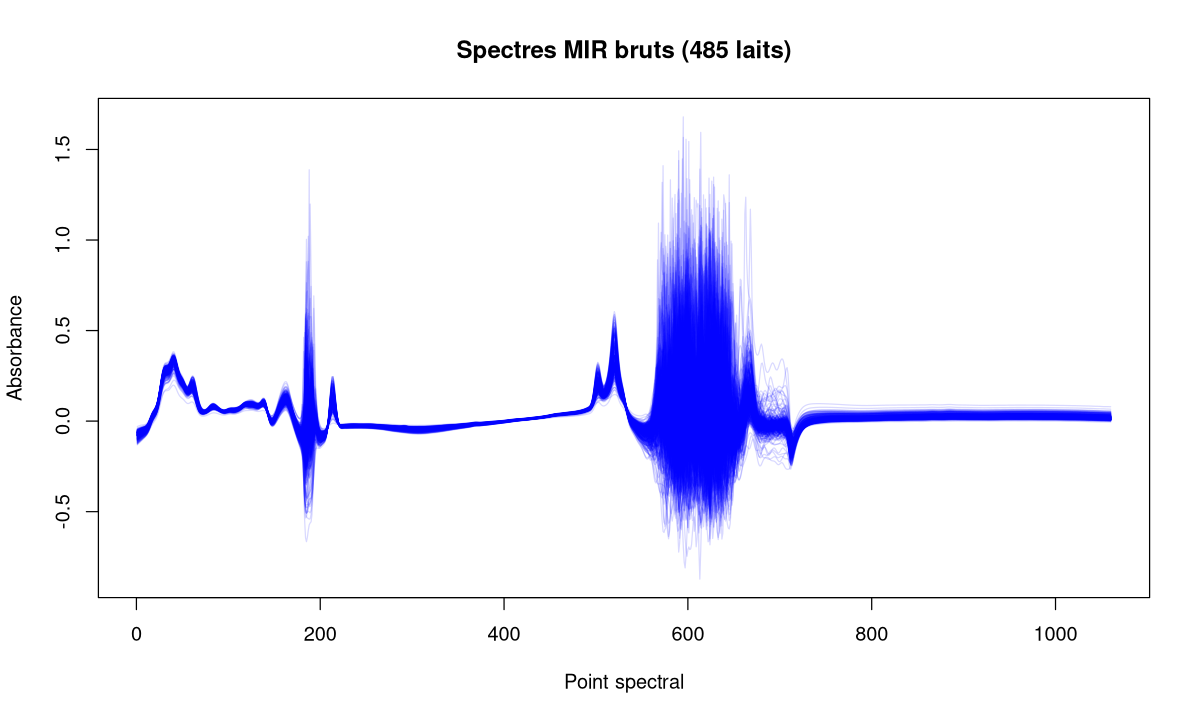

In [10]:
# Spectres bruts (cf. pca_fatty_acids.R) : une courbe par échantillon
matplot(t(x), type = "l", lty = 1, col = rgb(0, 0, 1, 0.15),
        xlab = "Point spectral", ylab = "Absorbance", main = "Spectres MIR bruts (485 laits)")

### 2.4.1 L'ACP et le choix du nombre de composantes

Comme pour les régressions pénalisées, on **standardise** les variables (`scale.unit = TRUE`) pour donner la même importance à tous les points spectraux.

> **Attention** (version du package) : avec FactoMineR 2.17 (installé ici), `$eig` ne contient plus que les `ncp` premières valeurs propres. Le Rmd officiel affichait toutes les valeurs propres après `PCA(x, scale = TRUE)` (ncp = 5 par défaut), ce qui n'est plus le cas. Pour voir la courbe complète du pourcentage cumulé, on demande toutes les composantes : `ncp = min(n - 1, p)` (c'est aussi ce que fait `pca_fatty_acids.R`).

In [11]:
ncp_max <- min(nrow(x) - 1, ncol(x))         # 484 composantes au maximum
res_pca <- PCA(x, scale.unit = TRUE, ncp = ncp_max, graph = FALSE)
dim(res_pca$eig)
round(head(res_pca$eig, 10), 3)

[1] 484   3

,eigenvalue,percentage of variance,cumulative percentage of variance
comp 1,456.263,43.044,43.044
comp 2,266.639,25.155,68.198
comp 3,129.278,12.196,80.394
comp 4,43.765,4.129,84.523
comp 5,27.121,2.559,87.082
comp 6,17.788,1.678,88.760
comp 7,10.228,0.965,89.725
comp 8,9.039,0.853,90.578
comp 9,7.979,0.753,91.330
comp 10,6.362,0.600,91.930


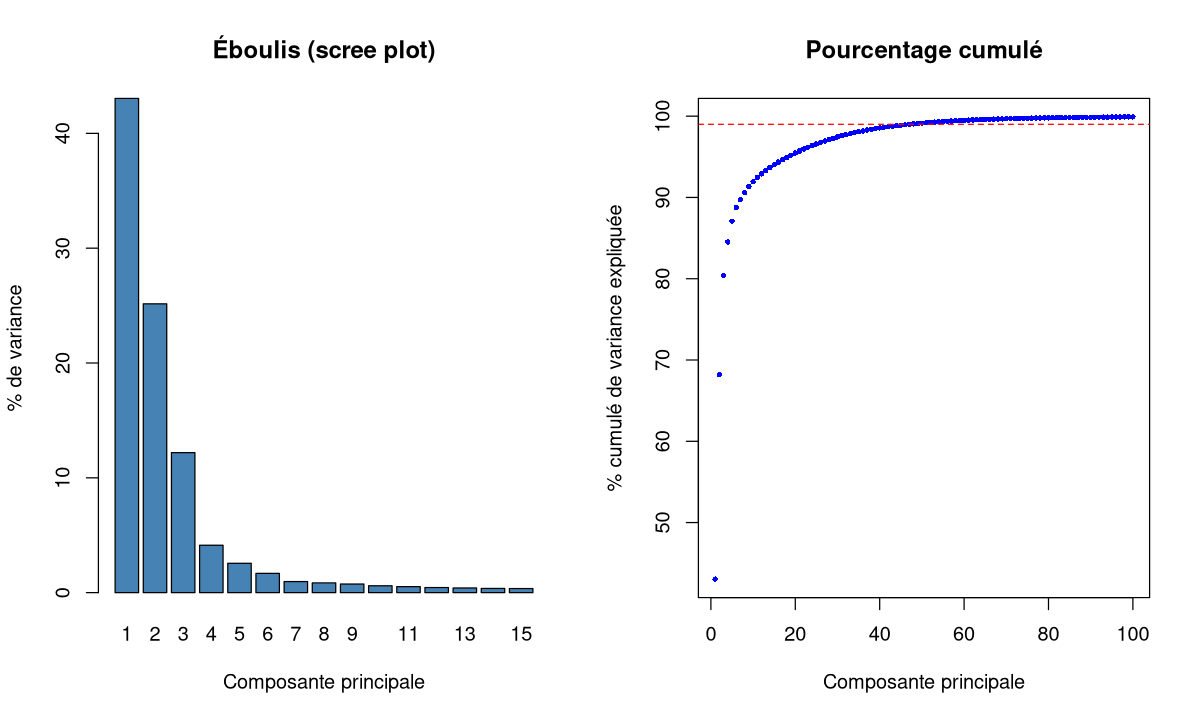

In [12]:
par(mfrow = c(1, 2))
# Éboulis des valeurs propres (scree plot) : % de variance des 15 premières composantes
barplot(res_pca$eig[1:15, 2], names.arg = 1:15, col = "steelblue",
        xlab = "Composante principale", ylab = "% de variance", main = "Éboulis (scree plot)")
# Pourcentage cumulé (cf. Rmd : 3e colonne de $eig)
plot(res_pca$eig[1:100, 3], col = "blue", pch = 16, cex = 0.6,
     xlab = "Composante principale", ylab = "% cumulé de variance expliquée",
     main = "Pourcentage cumulé")
abline(h = 99, lty = 2, col = "red")
par(mfrow = c(1, 1))

Les 3 premières composantes expliquent déjà 80 % de la variabilité des 1 060 points spectraux : les variables sont **très corrélées** (points spectraux adjacents). Le Rmd officiel retient le nombre de composantes qui explique **99 %** de la variabilité spectrale :

In [13]:
# Extrait du tableau des valeurs propres autour de 99 % (comme le Rmd)
round(res_pca$eig[(res_pca$eig[, 3] > 98.7) & (res_pca$eig[, 3] < 99.2), ], 4)

# Nombre de composantes nécessaires pour atteindre 90, 95, 99 et 99.9 % (cf. pca_fatty_acids.R)
sapply(c(90, 95, 99, 99.9), function(p) which(res_pca$eig[, 3] >= p)[1])

,eigenvalue,percentage of variance,cumulative percentage of variance
comp 43,0.7094,0.0669,98.7634
comp 44,0.6766,0.0638,98.8273
comp 45,0.6420,0.0606,98.8878
comp 46,0.5931,0.0560,98.9438
comp 47,0.5708,0.0539,98.9976
comp 48,0.5324,0.0502,99.0479
comp 49,0.5144,0.0485,99.0964
comp 50,0.4826,0.0455,99.1419
comp 51,0.4563,0.0430,99.1850


comp 8 comp 19 comp 48 comp 98 
      8      19      48      98

> **Attention** (incohérence entre les sources) : le Rmd officiel écrit « *A total of 47 principal components are needed to explain 99 %* ». En réalité, 47 composantes expliquent **98.998 %** (affiché « 99 » par `pander`, qui arrondit) ; il en faut **48** pour atteindre strictement 99 %. Le script `pca_fatty_acids.R` (`which(eig[, 3] >= 99)[1]`) trouve donc 48, alors que `pls_fatty_acids.R` et le Rmd utilisent 47. La différence est minime ; dans la suite, on garde **47** pour reproduire la correction officielle.

> **Complément** : le choix du seuil (99 %, 99.9 %…) est un compromis. Trop peu de composantes : on ignore des directions où un échantillon pourrait être atypique. Trop de composantes : les dernières décrivent surtout du bruit, et la distance de Mahalanobis donne autant de poids à ce bruit qu'aux grandes tendances (voir 2.6.2).

### 2.4.2 Le plan factoriel des individus

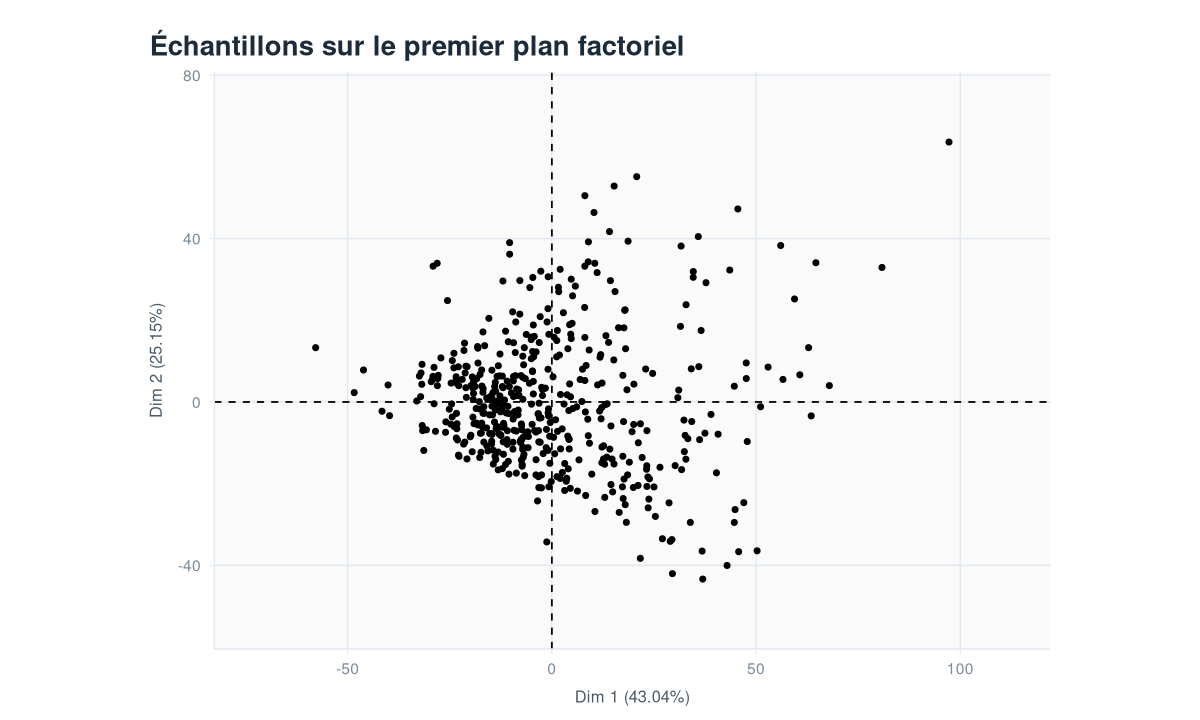

In [14]:
nPC <- 47
res_pca47 <- PCA(x, scale.unit = TRUE, ncp = nPC, graph = FALSE)
plot(res_pca47, choix = "ind", axes = c(1, 2), label = "none",
     title = "Échantillons sur le premier plan factoriel")

Le Rmd note que, sur les deux premières composantes, l'échantillon 96 semble se comporter différemment. Mais **deux dimensions ne suffisent pas** à représenter la variabilité spectrale (68 % seulement) : un échantillon peut sembler normal sur le premier plan et être très atypique sur la 30e composante. D'où l'intérêt d'une distance calculée sur **toutes** les composantes retenues.

> **Complément** : avec 1 060 variables, le graphe des variables (cercle des corrélations) est illisible. Il est plus parlant de tracer les corrélations variables–composante **le long du spectre** : on voit quelles régions spectrales « portent » chaque composante.

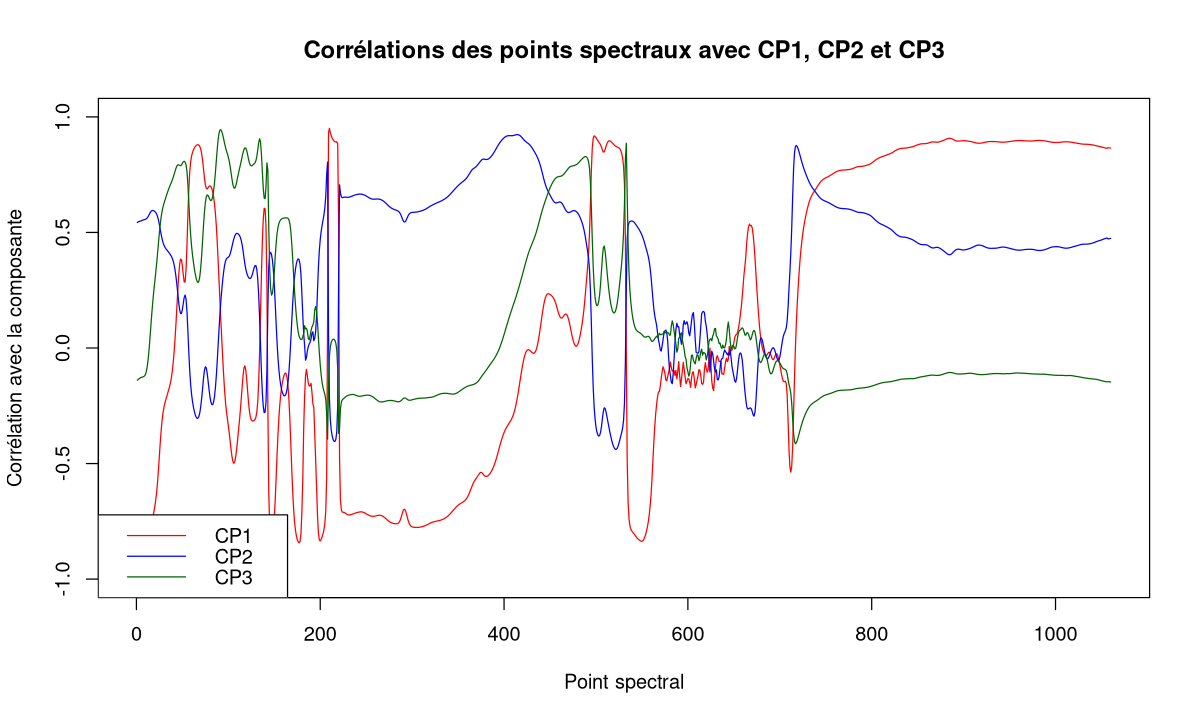

In [15]:
plot(res_pca47$var$cor[, 1], type = "l", col = "red", ylim = c(-1, 1),
     xlab = "Point spectral", ylab = "Corrélation avec la composante",
     main = "Corrélations des points spectraux avec CP1, CP2 et CP3")
lines(res_pca47$var$cor[, 2], col = "blue")
lines(res_pca47$var$cor[, 3], col = "darkgreen")
legend("bottomleft", legend = c("CP1", "CP2", "CP3"), col = c("red", "blue", "darkgreen"), lty = 1)

### Exercice 2.3 : combien de composantes ?
1. Combien de composantes faut-il pour expliquer 80 % puis 99.5 % de la variabilité spectrale ?
2. Quel pourcentage de variance explique la 47e composante **seule** ?
3. Fais un graphique du pourcentage cumulé pour les 60 premières composantes et ajoute des lignes horizontales à 95 % et 99 %.

In [16]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
sapply(c(80, 99.5), function(p) which(res_pca$eig[, 3] >= p)[1])
res_pca$eig[47, 2]          # % de variance de la 47e composante seule (environ 0.05 %)
plot(res_pca$eig[1:60, 3], type = "b", pch = 16, cex = 0.6,
     xlab = "Composante", ylab = "% cumulé")
abline(h = c(95, 99), lty = 2, col = c("orange", "red"))
```

La 47e composante n'explique qu'environ 0.05 % de la variabilité : les dernières composantes retenues décrivent des détails très fins des spectres.

</details>

---
## 2.5 La distance de Mahalanobis

### 2.5.1 Pourquoi pas la distance euclidienne ?

On veut mesurer à quel point un échantillon est **éloigné du barycentre** (le spectre moyen) du jeu de calibration. La distance euclidienne traite toutes les directions de la même façon. Or, le nuage de points est **allongé** dans certaines directions (grande variance) et **étroit** dans d'autres. Un écart de 1 unité dans une direction où la variance est minuscule est bien plus anormal qu'un écart de 1 unité dans la direction principale.

La **distance de Mahalanobis** corrige cela en tenant compte de la matrice de (co)variance $S$ :

$$D_i = \sqrt{(x_i - \mu)^T\, S^{-1}\, (x_i - \mu)}$$

> **Complément** : petite illustration en 2 dimensions avec des données simulées. Les points A et B sont pratiquement à la **même distance euclidienne** du centre, mais A est dans l'axe du nuage et B en travers.

euclid_A euclid_B   maha_A   maha_B 
2.111206 2.124457 1.600240 6.830194

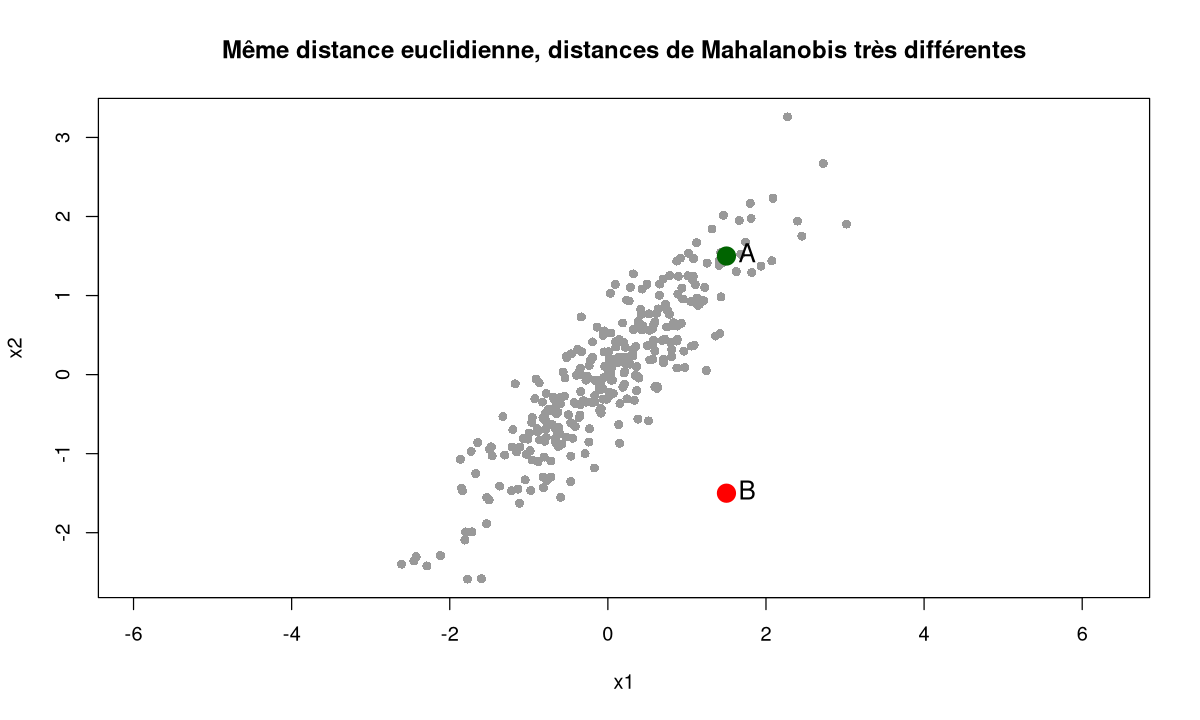

In [17]:
set.seed(2027)
sim <- MASS::mvrnorm(300, mu = c(0, 0), Sigma = matrix(c(1, 0.9, 0.9, 1), 2))   # données SIMULÉES, très corrélées
A <- c(1.5, 1.5); B <- c(1.5, -1.5)
plot(sim, pch = 16, col = "grey60", asp = 1, xlab = "x1", ylab = "x2",
     main = "Même distance euclidienne, distances de Mahalanobis très différentes")
points(rbind(A, B), pch = 19, col = c("darkgreen", "red"), cex = 2)
text(rbind(A, B), labels = c("A", "B"), pos = 4, cex = 1.3)
S <- cov(sim); mu <- colMeans(sim)
c(euclid_A = sqrt(sum((A - mu)^2)), euclid_B = sqrt(sum((B - mu)^2)),
  maha_A = sqrt(mahalanobis(A, mu, S)), maha_B = sqrt(mahalanobis(B, mu, S)))

### 2.5.2 Mahalanobis sur les composantes principales

Avec 1 060 variables très corrélées (et seulement 485 échantillons), la matrice $S$ des variables brutes n'est pas inversible. On calcule donc la distance **sur les composantes principales** (syllabus §3.5) :

$$D_i = \sqrt{(x_{PCA,i} - \mu_{PCA})^T\, S_{PCA}^{-1}\, (x_{PCA,i} - \mu_{PCA})}$$

où $x_{PCA,i}$ est le vecteur des scores de l'échantillon $i$, $\mu_{PCA}$ la moyenne des scores (le barycentre) et $S_{PCA}$ la matrice de variance-covariance des composantes retenues.

Les avantages (Rmd officiel) : 1) on travaille avec **moins de variables** ; 2) ces nouvelles variables sont **indépendantes** (corrélations nulles).

> **Attention** : dans le syllabus, la formule est écrite avec $S_{PCA}$ ; il faut lire l'**inverse** $S_{PCA}^{-1}$ (c'est bien ce que calcule `mahalanobis()`).

In [18]:
meanPC <- colMeans(res_pca47$ind$coord)   # barycentre (≈ 0 : les scores sont centrés)
covPC  <- cov(res_pca47$ind$coord)        # covariance entre composantes
round(range(meanPC), 12)
round(covPC[1:5, 1:5], 4)                 # diagonale = variances, hors diagonale = 0

[1] 0 0

,Dim.1,Dim.2,Dim.3,Dim.4,Dim.5
Dim.1,457.2059,0.0000,0.0000,0.0000,0.0000
Dim.2,0.0000,267.1904,0.0000,0.0000,0.0000
Dim.3,0.0000,0.0000,129.5456,0.0000,0.0000
Dim.4,0.0000,0.0000,0.0000,43.8556,0.0000
Dim.5,0.0000,0.0000,0.0000,0.0000,27.1769


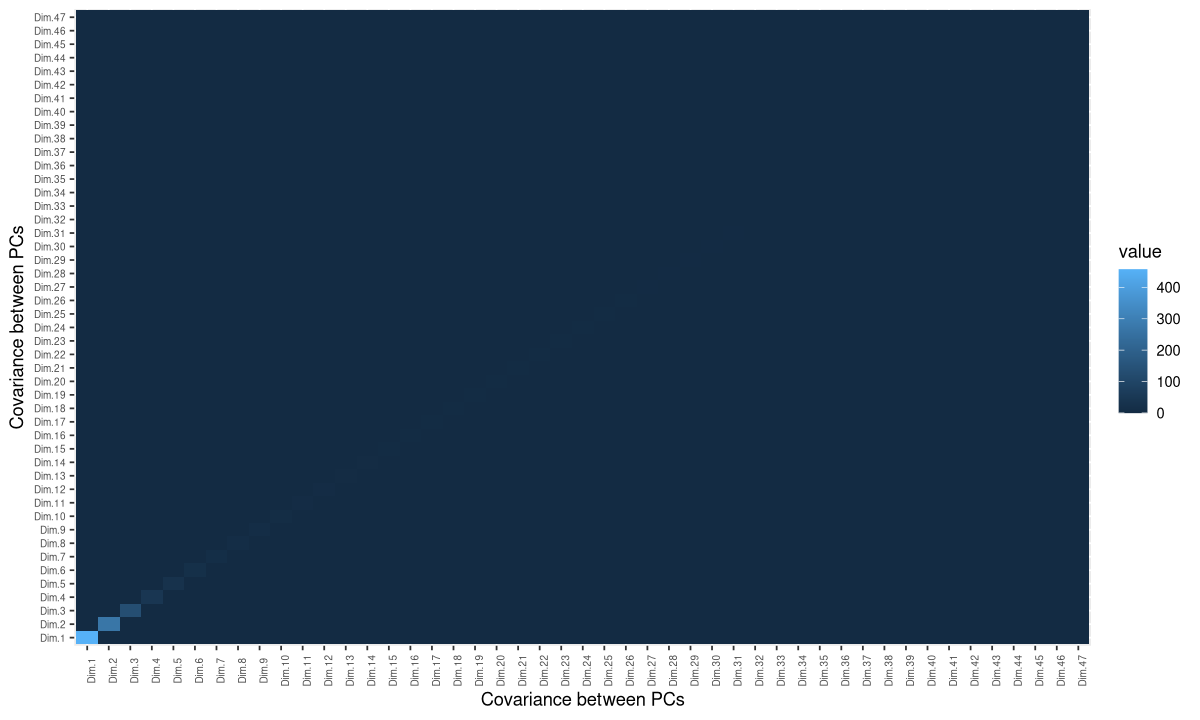

In [19]:
# Heatmap de la matrice de covariance (code du Rmd officiel, avec ggplot2 et reshape2)
melted_covPC <- melt(covPC)               # matrice -> tableau long (Var1, Var2, value)
ggplot(data = melted_covPC) + aes(x = Var1, y = Var2, fill = value) + geom_tile() +
  xlab("Covariance between PCs") + ylab("Covariance between PCs") +
  theme(axis.text.x = element_text(size = 6, angle = 90), axis.text.y = element_text(size = 6))

Comme le note le Rmd, toutes les covariances sont **nulles** ; seules les variances (diagonale) sont positives. Et même si les variables initiales ont été standardisées (variance 1), les composantes n'ont **pas** une variance de 1 : leur variance est la valeur propre (456 pour la première, 0.57 pour la 47e).

> **Fonction R** : `mahalanobis(x, center, cov, inverted = FALSE)`
>
> | Argument | Rôle |
> |---|---|
> | `x` | matrice (une ligne par individu) ou vecteur |
> | `center` | vecteur des moyennes (le barycentre) |
> | `cov` | matrice de covariance (ou son inverse si `inverted = TRUE`) |
>
> **Renvoie** le **carré** de la distance, $D_i^2 = (x_i-\mu)^T S^{-1}(x_i-\mu)$, pour chaque ligne.

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  17.98   32.70   42.51   46.90   56.41  192.77 

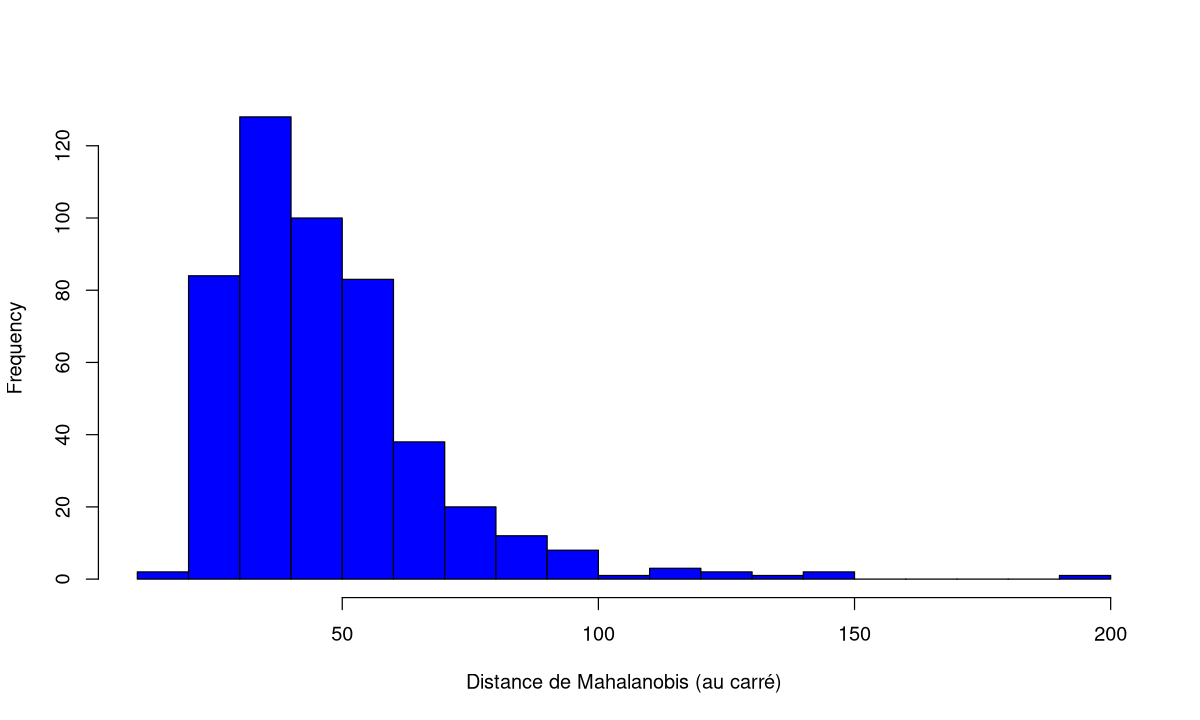

In [20]:
maha <- mahalanobis(res_pca47$ind$coord, center = meanPC, cov = covPC)
summary(maha)
hist(maha, xlab = "Distance de Mahalanobis (au carré)", col = "blue", main = NULL, breaks = 20)

On retrouve les valeurs du Rmd (min 17.98, médiane 42.51, moyenne 46.90, max 192.8).

> **Attention** (vocabulaire des sources) : `mahalanobis()` renvoie $D^2$ et non $D$. Le syllabus définit $D$ (avec la racine) puis divise « cette distance » par le nombre de composantes ; le Rmd officiel et les scripts divisent $D^2$. C'est **$D^2/n_{PC}$** que l'on appelle GH dans la pratique (et dans la suite du cours) : c'est cette version qui a une moyenne proche de 1 et pour laquelle les seuils 3 et 5 ont été établis.

### Exercice 2.4 : Mahalanobis à la main
Comme la matrice de covariance des composantes est **diagonale**, la distance de Mahalanobis se simplifie : $D_i^2 = \sum_{k} \dfrac{(z_{ik} - \bar z_k)^2}{s_k^2}$.
1. Calcule `D2_main` pour les 485 échantillons avec cette formule (indice : `sweep()` ou `scale()`).
2. Vérifie que tu obtiens les mêmes valeurs que `maha`.

In [21]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
coord <- res_pca47$ind$coord
D2_main <- rowSums(scale(coord)^2)        # (z - moyenne)^2 / variance, sommé sur les composantes
all.equal(unname(D2_main), unname(maha))  # TRUE
```

`scale(coord)` centre chaque composante et la divise par son écart-type : élever au carré et sommer donne exactement $D^2$. C'est la forme « standardisée » de la distance euclidienne, qui n'est valable que parce que les composantes sont non corrélées.

</details>

---
## 2.6 La distance GH et le nettoyage du jeu de calibration

### 2.6.1 Définition et seuils

Le Rmd le remarque : la distance de Mahalanobis dépend **directement du nombre de composantes** utilisées ; sa moyenne (46.90) est à peu près égale au nombre de composantes (47). On la standardise donc en la divisant par ce nombre : c'est la **distance GH** (*Global H*).

$$GH_i = \frac{D_i^2}{n_{PC}}$$

> **Complément** : ce n'est pas un hasard. Sur les données de calibration, la moyenne de $D^2$ vaut **exactement** $n_{PC}\,(n-1)/n$ (ici $47 \times 484/485 = 46.90$). La moyenne de GH vaut donc presque 1, quel que soit le nombre de composantes.

Règles d'interprétation (syllabus §3.5) :

| GH | Interprétation |
|---|---|
| < 3 | l'échantillon est dans la **variabilité** du jeu de calibration |
| entre 3 et 5 | zone intermédiaire : échantillon à surveiller |
| > 5 | **outlier spectral** par rapport au jeu de calibration |

In [22]:
GH <- maha / nPC
summary(GH)
c(moyenne_D2 = mean(maha), theorique = nPC * (nrow(x) - 1) / nrow(x))

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.3825  0.6958  0.9044  0.9979  1.2003  4.1015 

moyenne_D2  theorique 
  46.90309   46.90309

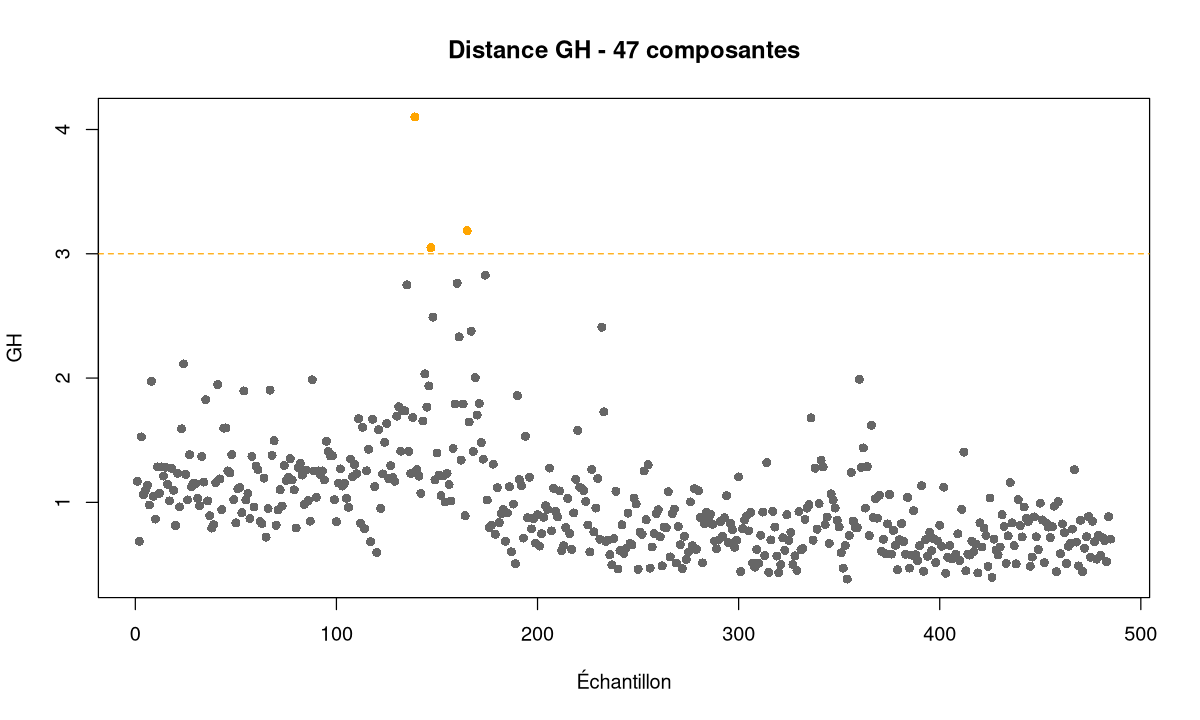

In [23]:
# Graphe des GH par échantillon avec les deux seuils (cf. pca_fatty_acids.R)
plot(GH, pch = 16, col = ifelse(GH > 5, "red", ifelse(GH >= 3, "orange", "grey40")),
     xlab = "Échantillon", ylab = "GH", main = paste("Distance GH -", nPC, "composantes"))
abline(h = c(3, 5), lty = 2, col = c("orange", "red"))

In [24]:
# Échantillons avec GH >= 3 et leur teneur en SAT
suspects <- data.frame(sampleID = fattyacid$sampleID, GH = round(GH, 3), SAT = y)[GH >= 3, ]
suspects[order(-suspects$GH), ]
c(GH_sup3 = sum(GH >= 3), GH_sup5 = sum(GH > 5))

,sampleID,GH,SAT
,<int>,<dbl>,<dbl>
139,139,4.102,3.514
165,165,3.186,2.455
147,147,3.049,4.491


GH_sup3 GH_sup5 
      3       0

Trois échantillons (139, 147 et 165) ont un GH ≥ 3, et aucun ne dépasse 5. Le Rmd officiel applique le seuil 3 et les retire : il reste **482** échantillons pour la calibration (c'est aussi ce que fait `pls_fatty_acids.R`). Le script `pca_fatty_acids.R`, lui, ne retire que les GH > 5, donc aucun échantillon ici.

In [25]:
# Nettoyage (code du Rmd officiel) : on garde les échantillons avec GH < 3
newX <- x[GH < 3, ]
newy <- y[GH < 3]
dim(newX); length(newy)

[1]  482 1060

[1] 482

> **Attention** : ce nettoyage ne porte que sur **X** (les spectres). Le Rmd précise qu'on pourrait aussi faire un second nettoyage sur **y** (statistiques descriptives, valeurs extrêmes), et qu'on pourrait d'abord retirer les régions spectrales bruitées (homework 1) avant de calculer les distances. Ce n'est pas fait ici.

### 2.6.2 Le GH dépend du nombre de composantes

In [26]:
# Sensibilité du nombre d'outliers au nombre de composantes retenues
sapply(c(5, 10, 20, 47, 100, 200), function(k) {
  coord_k <- res_pca$ind$coord[, 1:k]
  gh_k <- mahalanobis(coord_k, colMeans(coord_k), cov(coord_k)) / k
  c(nPC = k, GH_sup3 = sum(gh_k >= 3), GH_sup5 = sum(gh_k > 5))
})

nPC,5,10,20,47,100,200
GH_sup3,21,17,7,3,1,0
GH_sup5,8,4,1,0,0,0


Le nombre d'échantillons signalés **diminue** quand on augmente le nombre de composantes : avec 5 composantes, 21 laits ont un GH ≥ 3 ; avec 47, il n'en reste que 3 ; avec 200, aucun. Deux effets se combinent :

- avec **peu** de composantes, un écart marqué sur une des grandes tendances pèse lourd, puisqu'on ne divise que par 5. En revanche, un échantillon atypique seulement dans une direction « fine » passe inaperçu ;
- avec **beaucoup** de composantes, un écart sur quelques composantes est « dilué » dans la division par $n_{PC}$, et on donne autant de poids à des directions qui ne décrivent presque que du bruit.

Le commentaire de `pca_fatty_acids.R` le rappelle : « *the GH values depend strongly on this choice* ». Le nombre de composantes doit donc être fixé selon une règle claire (ici 99 % de variance) et toujours **précisé** dans un rapport.

### Exercice 2.5 : un échantillon suspect à la loupe
1. Trace en gris quelques spectres « normaux » (par exemple les 30 premiers) et superpose en rouge le spectre de l'échantillon au plus grand GH.
2. Dans quelle(s) région(s) spectrale(s) se distingue-t-il ?

In [27]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
pire <- which.max(GH)
matplot(t(x[1:30, ]), type = "l", lty = 1, col = "grey70",
        xlab = "Point spectral", ylab = "Absorbance",
        main = paste("Échantillon", fattyacid$sampleID[pire], "- GH =", round(GH[pire], 2)))
lines(as.numeric(x[pire, ]), col = "red", lwd = 2)
```

Un GH élevé ne signifie pas forcément un spectre visiblement « cassé » : l'écart peut être réparti sur des combinaisons fines de points spectraux, invisibles à l'œil mais captées par les composantes de faible variance. C'est tout l'intérêt de la distance multivariée.

</details>

### Exercice 2.6 : un autre seuil
Le script `pca_fatty_acids.R` retient le nombre de composantes qui atteint 99 % **au sens strict** (48 composantes) et le seuil GH > 5.
1. Recalcule les GH avec 48 composantes.
2. Combien d'échantillons dépassent 3 ? Et 5 ? Les échantillons repérés sont-ils les mêmes qu'avec 47 composantes ?

In [28]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
coord48 <- res_pca$ind$coord[, 1:48]
GH48 <- mahalanobis(coord48, colMeans(coord48), cov(coord48)) / 48
c(GH_sup3 = sum(GH48 >= 3), GH_sup5 = sum(GH48 > 5))
fattyacid$sampleID[GH48 >= 3]
fattyacid$sampleID[GH >= 3]
```

Passer de 47 à 48 composantes change très peu les distances : on repère les mêmes échantillons. La conclusion est robuste à ce petit changement, mais elle ne l'est pas forcément pour des changements plus importants (voir le tableau de sensibilité ci-dessus).

</details>

---
## 2.7 Potentiel de prédiction d'un nouvel échantillon

Une équation de prédiction n'est fiable que pour des échantillons **semblables** à ceux de la calibration. Le syllabus (§3.5) recommande donc de vérifier, **avant de prédire**, que les variables explicatives du nouvel échantillon sont incluses dans la variabilité du jeu de calibration :

1. on **projette** le nouvel échantillon sur l'ACP de la calibration (mêmes moyennes, mêmes écarts-types, mêmes vecteurs propres) ;
2. on calcule son GH par rapport au **barycentre et à la covariance de la calibration** ;
3. GH < 3 : la prédiction peut être faite ; GH > 5 : l'échantillon est un outlier par rapport à la calibration. Soit son spectre a été mal mesuré, soit la calibration ne couvre pas encore assez de variabilité, et il faudra l'enrichir.

> **Fonction R** : `predict(res_pca, newdata)` (méthode `predict.PCA` de FactoMineR) projette de nouveaux individus. `newdata` doit avoir **les mêmes colonnes** (mêmes noms, même ordre) que les données de l'ACP. Elle renvoie `$coord` (coordonnées), `$cos2` et `$dist`.

On l'applique au jeu indépendant `validation_fatty_acids.csv` (338 laits, voir partie 0), qui servira à la validation externe en partie 5.

In [29]:
validation <- read.table(file = "../validation_fatty_acids.csv", sep = ";", header = TRUE)
dim(validation)                                        # 338 x 1062 : SampleID, SAT, X1...X1060
valid_spectra <- validation[, 3:1062]
identical(names(valid_spectra), names(x))              # mêmes noms de colonnes que la calibration

proj <- predict(res_pca47, newdata = valid_spectra)   # projection sur l'ACP de calibration
GH_valid <- mahalanobis(proj$coord, center = meanPC, cov = covPC) / nPC
summary(GH_valid)
c(GH_sup3 = sum(GH_valid >= 3), GH_sup5 = sum(GH_valid > 5))

[1]  338 1062

[1] TRUE

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.5070  0.8345  0.9894  1.3762  1.2487 98.8296 

GH_sup3 GH_sup5 
      2       1

,SampleID,SAT
,<int>,<dbl>
64,64,1.624859
139,139,2.232112


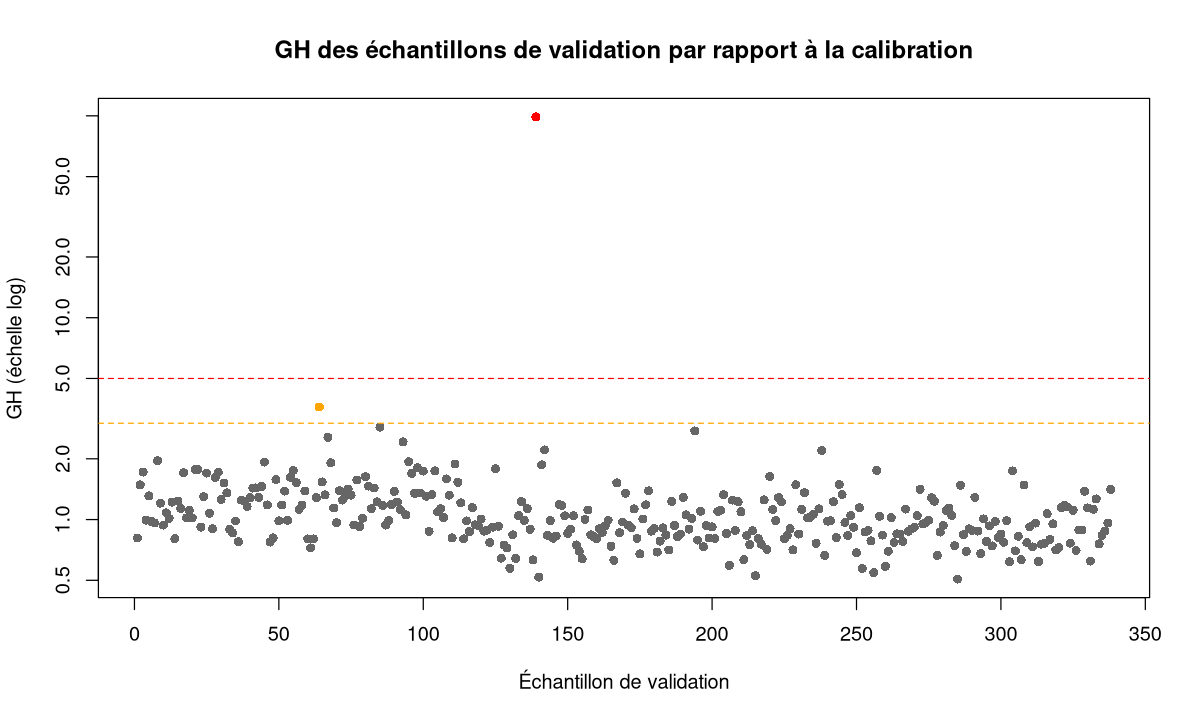

In [30]:
plot(GH_valid, pch = 16, log = "y",
     col = ifelse(GH_valid > 5, "red", ifelse(GH_valid >= 3, "orange", "grey40")),
     xlab = "Échantillon de validation", ylab = "GH (échelle log)",
     main = "GH des échantillons de validation par rapport à la calibration")
abline(h = c(3, 5), lty = 2, col = c("orange", "red"))
validation[GH_valid >= 3, c("SampleID", "SAT")]

L'immense majorité des échantillons de validation sont dans la variabilité de la calibration. Un échantillon a un GH énorme (près de 100) : son spectre est totalement en dehors de ce que le modèle a « vu ». Sa prédiction ne serait pas fiable, et il faudrait vérifier la mesure de son spectre.

> **Attention** : on calcule le GH des nouveaux échantillons avec le barycentre et la covariance **de la calibration** (`meanPC`, `covPC`), jamais avec ceux du nouveau jeu. Sinon, on mesurerait leur atypicité entre eux, et non par rapport au modèle.

### Exercice 2.7 : contrôle avant prédiction
Écris une fonction `controle_GH(res_pca, newdata, nPC, seuil = 3)` qui renvoie un `data.frame` avec, pour chaque nouvel échantillon, son GH et un statut parmi `"OK"`, `"à surveiller"` (entre 3 et 5) et `"outlier"` (> 5). La fonction doit recalculer le barycentre et la covariance à partir de `res_pca$ind$coord`. Teste-la sur `valid_spectra` et affiche le nombre d'échantillons par statut.

In [31]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
controle_GH <- function(res_pca, newdata, nPC) {
  coord_cal <- res_pca$ind$coord[, 1:nPC]
  coord_new <- predict(res_pca, newdata = newdata)$coord[, 1:nPC]
  gh <- mahalanobis(coord_new, colMeans(coord_cal), cov(coord_cal)) / nPC
  statut <- ifelse(gh > 5, "outlier", ifelse(gh >= 3, "à surveiller", "OK"))
  data.frame(GH = round(gh, 3), statut = statut)
}
ctrl <- controle_GH(res_pca47, valid_spectra, nPC = 47)
table(ctrl$statut)
```

Cette fonction est réutilisable pour n'importe quel jeu de données : c'est exactement le contrôle à faire en routine avant d'appliquer une équation de prédiction à de nouveaux spectres.

</details>

### Exercice 2.8 : GH et teneur en SAT
Les échantillons atypiques sur le plan spectral le sont-ils aussi pour la variable à prédire ? Trace SAT en fonction du GH pour le jeu de calibration (485 échantillons), avec une ligne verticale à GH = 3. Calcule la moyenne de SAT pour GH < 3 et GH ≥ 3.

In [32]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
plot(GH, y, pch = 16, col = ifelse(GH >= 3, "red", "grey40"),
     xlab = "GH", ylab = "SAT (g/dl)")
abline(v = 3, lty = 2, col = "red")
tapply(y, GH >= 3, mean)
```

Un outlier spectral n'est pas forcément un outlier en *y*. C'est une question à se poser avant de retirer des échantillons : on verra dans le homework 2 (sols) que les échantillons à GH élevé sont parfois justement ceux qui ont les teneurs les plus élevées, et qu'il vaut alors mieux les garder.

</details>

---
## Questions de compréhension

**Q1.** Pourquoi la contrainte $\sum_j u_{j1}^2 = 1$ est-elle indispensable pour définir la première composante ?

**Q2.** Vrai ou faux : dans une ACP normée, chaque composante principale a une variance de 1.

**Q3.** Pourquoi calcule-t-on la distance de Mahalanobis sur les composantes principales plutôt que sur les 1 060 points spectraux ?

**Q4.** Un échantillon a un GH de 4.2. Que fais-tu ?

**Q5.** Pour évaluer si un nouvel échantillon peut être prédit, faut-il calculer son GH avec la moyenne et la covariance du jeu de calibration ou du nouveau jeu ?

<details>
<summary><b>Voir les réponses</b></summary>

**Q1.** Sans elle, on pourrait augmenter la variance de la composante à l'infini en multipliant tous les coefficients par une constante : le problème « variance maximale » n'aurait pas de solution.

**Q2.** Faux. Ce sont les **variables** qui ont une variance de 1. La variance de la composante $k$ est sa valeur propre $\lambda_k$ (456 pour la première composante des spectres, 0.57 pour la 47e).

**Q3.** Avec 1 060 variables très corrélées et 485 échantillons, la matrice de covariance des variables brutes n'est pas inversible. Sur les composantes : on a moins de variables, elles sont non corrélées (covariance diagonale, facile à inverser), et on ne garde que les directions qui décrivent l'essentiel de la variabilité.

**Q4.** Il est au-dessus du seuil 3 mais sous 5 : il est en marge de la variabilité de la calibration. On vérifie son spectre et son origine. Pour la calibration, le Rmd officiel retire les GH ≥ 3 ; le script `pca_fatty_acids.R` ne retire que les GH > 5. Il faut justifier son choix (et, idéalement, comparer les performances des modèles avec et sans ces échantillons, comme au homework 2).

**Q5.** Avec ceux du **jeu de calibration** : la question est « cet échantillon ressemble-t-il à ce que le modèle a appris ? ».

</details>

---
## Récapitulatif

- L'ACP résume des variables très corrélées par des **composantes** : combinaisons linéaires normées, de variance maximale décroissante, **orthogonales** (non corrélées). Vecteurs propres = coefficients ; valeurs propres = variances.
- Sur les spectres MIR du lait, 3 composantes expliquent 80 % et 47 à 48 composantes 99 % de la variabilité des 1 060 points spectraux.
- La **distance de Mahalanobis** sur les composantes mesure l'éloignement d'un échantillon au barycentre en tenant compte de la forme du nuage. `mahalanobis()` renvoie $D^2$.
- **GH** = $D^2 / n_{PC}$ (moyenne ≈ 1) : GH < 3 dans la variabilité, GH > 5 outlier spectral. Avec 47 composantes, 3 laits ont un GH ≥ 3 et sont retirés (482 restent).
- Avant de prédire de nouveaux échantillons, on les **projette** sur l'ACP de calibration et on vérifie leur GH (potentiel de prédiction).

| Fonction | Rôle |
|---|---|
| `eigen(cor(X))` | vecteurs et valeurs propres |
| `prcomp(X, scale. = TRUE)` | ACP de base R (`$sdev`, `$rotation`, `$x`) |
| `FactoMineR::PCA(X, scale.unit, ncp, graph)` | ACP du cours (`$eig`, `$ind$coord`, `$var$cor`, `$svd$V`) |
| `plot(res, choix = "ind", axes, label)` | plan factoriel des individus |
| `predict(res_pca, newdata)` | projection de nouveaux individus |
| `mahalanobis(x, center, cov)` | distance de Mahalanobis **au carré** |
| `matplot(t(X), type = "l")` | tracer tous les spectres |
| `melt()` + `ggplot(...) + geom_tile()` | heatmap d'une matrice |

**Suite** : `03_Regression_sur_composantes_principales_PCR` : utiliser les composantes principales comme variables explicatives d'une régression.